# Arquitecturas de redes recurrentes para pronosticar (PyTorch)

En la presentación **Arquitecturas y práctica** vimos que una red recurrente se puede usar con cuatro arquitecturas, según qué entra a la red y qué sale de ella:

| Arquitectura | Qué entra | Qué sale |
|---|---|---|
| 1. Secuencia → vector | una serie | un vector (aquí, los 14 días siguientes juntos) |
| 2. Secuencia → secuencia | una serie | una predicción en cada paso |
| 3. Vector → secuencia | unos pocos números | una serie, generada un valor por paso |
| 4. Codificador–decodificador | una serie | otra serie, con otro largo |

En este notebook programamos las cuatro con **un mismo problema y un mismo dataset**, para que lo único que cambie de una sección a otra sea la arquitectura.

**El problema.** La empresa de transporte de Chicago (CTA) tiene que decidir con anticipación cuántos trenes pone a circular y cuánto personal programa cada día. Esos turnos se arman con unas dos semanas de anticipación, así que no le basta con saber cuánta gente viajará mañana: necesita **un pronóstico para cada uno de los próximos 14 días**. Para hacerlo tenemos el registro de cuántas personas entraron al metro cada día durante los últimos años (es el mismo dataset del notebook de la red recurrente simple; abajo lo explicamos de nuevo).

**El plan.** Cada arquitectura tiene su propia sección (etapas 3 a 6) con:

1. **La idea:** qué entra, qué sale y en qué situación del problema tiene sentido esa arquitectura.
2. **El esquema** de la arquitectura, como en la presentación.
3. **Los ejemplos:** una tabla y una gráfica que muestran quién es X (lo que entra) y quién es y (lo que debe salir).
4. **La red**, su entrenamiento y **su pronóstico** en un ejemplo que la red nunca vio.

Al final (etapa 7) comparamos los errores de las cuatro.

Todas usan celdas **GRU** (del notebook de LSTM y GRU). La clase para entrenar es la de los notebooks anteriores, así que va sin explicación aparte.

## Etapa 1: Se carga la base de datos

In [1]:
import copy
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from tqdm import tqdm

INDIGO, TEAL, CORAL = "#3A47B5", "#0B8570", "#C03F32"   # colores de la presentación: lo que entra, lo que sale y el pronóstico

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
data_dir = Path("data")
csv_path = data_dir / "ridership" / "CTA_-_Ridership_-_Daily_Boarding_Totals.csv"
if not csv_path.exists():
    data_dir.mkdir(exist_ok=True)
    tgz_path, _ = urllib.request.urlretrieve("https://github.com/ageron/data/raw/main/ridership.tgz",
                                             data_dir / "ridership.tgz")
    with tarfile.open(tgz_path) as f:
        f.extractall(data_dir, filter="data")

df = pd.read_csv(csv_path, parse_dates=["service_date"], date_format="%m/%d/%Y")
df.columns = ["date", "day_type", "bus", "rail", "total"]
df = df.sort_values("date").set_index("date")
df = df.drop("total", axis=1)      # total = bus + rail, no aporta nada nuevo
df = df.drop_duplicates()          # el archivo trae algunos días repetidos
rail = df["rail"]
rail.head()

date
2001-01-01    126455
2001-01-02    501952
2001-01-03    536432
2001-01-04    550011
2001-01-05    557917
Name: rail, dtype: int64

### ¿De qué trata el dataset?

La CTA publica, desde 2001, **cuántas personas entraron a su sistema cada día**. Cada fila del archivo es un día y tiene cuatro columnas:

- `date`: la fecha.
- `day_type`: el tipo de día. `W` es un día laboral (lunes a viernes), `A` es sábado y `U` es domingo o festivo.
- `bus`: cuántas personas subieron a los buses ese día.
- `rail`: cuántas personas entraron al metro ese día. **Esta es la serie que vamos a pronosticar.**

Así que la serie es una lista de números, uno por día: $x_1, x_2, x_3, \dots$, donde cada número es la cantidad de personas que usaron el metro ese día. Veamos cómo se ve, primero en cuatro años y luego en tres semanas:

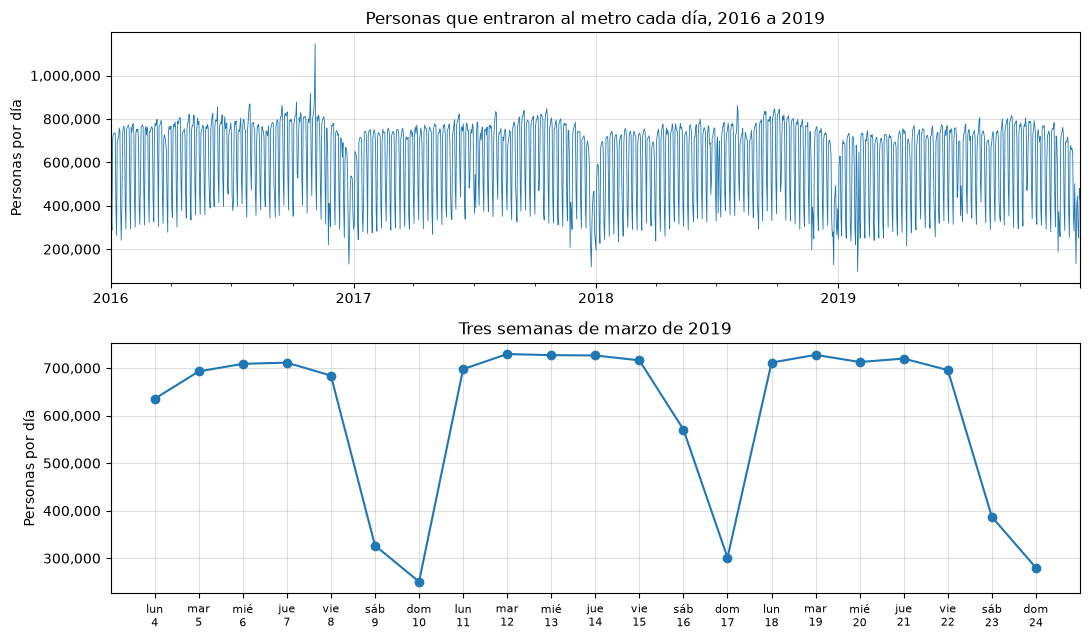

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5))
rail["2016":"2019"].plot(ax=ax1, lw=0.6)
ax1.set_title("Personas que entraron al metro cada día, 2016 a 2019"); ax1.set_xlabel(""); ax1.grid(alpha=0.4)

three_weeks = rail["2019-03-04":"2019-03-24"]
ax2.plot(three_weeks.index, three_weeks.values, "o-")
ax2.set_xticks(three_weeks.index)
ax2.set_xticklabels([f"{['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom'][d.day_of_week]}\n{d.day}" for d in three_weeks.index], fontsize=8)
ax2.set_title("Tres semanas de marzo de 2019"); ax2.grid(alpha=0.4)
for ax in (ax1, ax2):
    ax.set_ylabel("Personas por día")
    ax.yaxis.set_major_formatter(lambda v, pos: f"{v:,.0f}")   # 700,000 en vez de 0.7 × 1e6
plt.tight_layout(); plt.show()

Lo que hay que notar:

- **Un patrón semanal muy marcado:** de lunes a viernes entran unas 700 000 a 800 000 personas (la gente va a trabajar y a estudiar); el sábado baja a unas 430 000 y el domingo a unas 320 000. Ese patrón se repite cada 7 días.
- **Los festivos** se parecen a un domingo: son los picos hacia abajo que aparecen sueltos en la gráfica de arriba (Navidad, Año Nuevo, Día de Acción de Gracias…).
- **El nivel cambia despacio:** en diciembre y enero viaja menos gente (vacaciones y frío), y de un año a otro el promedio baja poco a poco: de unas 650 000 personas por día en 2016 a unas 600 000 en 2019.

Por eso, para pronosticar las próximas dos semanas, la red tiene que saber **en qué día de la semana va** y **cuál es el nivel reciente**. Con **56 días** de historia (8 semanas) ve el patrón semanal ocho veces y sabe cuánta gente está viajando últimamente. Esa es la ventana que usamos: **la red lee 56 días y pronostica los 14 siguientes**.

### Entrenamiento, validación y test

Dividimos en el tiempo: 2016 a 2018 para entrenar, enero a mayo de 2019 para validar y junio a diciembre de 2019 para test. Cada periodo de validación y test empieza con los 56 días anteriores, para que su primera ventana esté completa.

In [4]:
window_length, horizon = 56, 14   # la red lee 56 días y pronostica los 14 siguientes

def period(start, end):
    # Los días entre start y end, más los window_length días anteriores
    first = rail.index.get_loc(rail[start:].index[0])
    last = rail.index.get_loc(rail[:end].index[-1])
    return rail.iloc[max(first - window_length, 0):last + 1]

rail_train = rail["2016-01":"2018-12"]
rail_valid = period("2019-01", "2019-05")
rail_test = period("2019-06", "2019-12")
print("Días de entrenamiento, validación y test:", len(rail_train), len(rail_valid), len(rail_test))

Días de entrenamiento, validación y test: 1096 207 270


## Etapa 2: Herramientas que usan las cuatro arquitecturas

Antes de empezar dejamos listas dos cosas que se repiten en todas las secciones. Ninguna es nueva:

- `WindowDataset`: corta la serie en ventanas. X son 56 días seguidos y y los 14 días siguientes. Los valores se dividen entre un millón para que queden cerca de 1.
- `Forecaster`: la clase para entrenar de los notebooks anteriores (`train_epoch`, `evaluate`, `fit` y `predict`), que ahora recibe la red ya armada, porque cada arquitectura tiene la suya.

In [5]:
scale = 1e6  # los pasajeros se dividen entre un millón

class WindowDataset(Dataset):
    def __init__(self, series, window_length=56, horizon=14):
        self.values = torch.tensor(series.values / scale, dtype=torch.float32)
        self.dates = series.index
        self.window_length = window_length
        self.horizon = horizon

    def __len__(self):
        return len(self.values) - self.window_length - self.horizon + 1

    def __getitem__(self, idx):
        end = idx + self.window_length
        X = self.values[idx:end].unsqueeze(-1)       # (56, 1): 56 pasos con 1 variable
        y = self.values[end:end + self.horizon]      # (14,): los 14 días siguientes
        return X, y


def stack(dataset):
    # Junta todos los ejemplos de un dataset en dos tensores (sin iterar el Dataset directamente)
    pairs = [dataset[i] for i in range(len(dataset))]
    return torch.stack([p[0] for p in pairs]), torch.stack([p[1] for p in pairs])


def windows_table(dataset, n=5, x_name="x"):
    # Una fila por ejemplo: columnas x_1 ... x_T (la entrada X) y y_1 ... y_H (la etiqueta y), en personas
    rows = []
    for i in range(n):
        X, y = dataset[i]
        row = {f"{x_name}_{t + 1}": X[t, 0].item() * scale for t in range(len(X))}
        row.update({f"y_{h + 1}": y[h].item() * scale for h in range(len(y))})
        rows.append(row)
    with pd.option_context("display.max_columns", 12):
        display(pd.DataFrame(rows, index=[f"ejemplo {i + 1}" for i in range(n)]).round().astype(int))

In [6]:
class Forecaster:
    def __init__(self, net, lr=3e-3):
        self.net = net.to(device)
        self.loss_fn = nn.HuberLoss()
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=lr)
        self.history = {"loss": [], "mae": [], "val_loss": [], "val_mae": []}

    def train_epoch(self, loader):
        # Una época: recorre todos los minibatches y actualiza los pesos
        self.net.train()
        total_loss, total_abs, n = 0.0, 0.0, 0
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            y_pred = self.net(X, target=y)   # target solo lo usan las redes con decodificador
            loss = self.loss_fn(y_pred, y)
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item() * len(X)
            total_abs += (y_pred - y).abs().sum().item()
            n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * scale

    def evaluate(self, loader):
        # Mide el desempeño sin entrenar (sin calcular gradientes)
        self.net.eval()
        total_loss, total_abs, n = 0.0, 0.0, 0
        with torch.no_grad():
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                y_pred = self.net(X)
                total_loss += self.loss_fn(y_pred, y).item() * len(X)
                total_abs += (y_pred - y).abs().sum().item()
                n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * scale

    def fit(self, train_set, valid_set, epochs=100, batch_size=32):
        train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
        valid_loader = DataLoader(valid_set, batch_size=batch_size)
        best_mae, best_state = float("inf"), None
        pbar = tqdm(range(epochs), desc="Entrenamiento", unit="época")
        for epoch in pbar:
            loss, mae = self.train_epoch(train_loader)
            val_loss, val_mae = self.evaluate(valid_loader)
            for key, value in zip(self.history, (loss, mae, val_loss, val_mae)):
                self.history[key].append(value)
            if val_mae < best_mae:  # guardamos los mejores pesos
                best_mae, best_state = val_mae, copy.deepcopy(self.net.state_dict())
            pbar.set_postfix(mae=f"{mae:,.0f}", val_mae=f"{val_mae:,.0f}", mejor_val_mae=f"{best_mae:,.0f}")
        self.net.load_state_dict(best_state)  # nos quedamos con los mejores pesos
        print(f"Mejor MAE de validación: {best_mae:,.0f} personas")

    def predict(self, X):
        # Devuelve el pronóstico (dividido entre un millón) para cada ejemplo
        self.net.eval()
        with torch.no_grad():
            return self.net(X.to(device)).cpu()

## Etapa 3: Arquitectura 1, secuencia → vector

**Qué entra:** la serie de los últimos 56 días, $X = (x_1, \dots, x_{56})$. **Qué sale:** un vector con los 14 días siguientes, $\hat y = (\hat y_1, \dots, \hat y_{14})$.

La red lee toda la ventana; las salidas de los pasos 1 a 55 no se usan. Solo el último estado, $h_{56}$, que resume lo leído, pasa a una capa densa con **14 neuronas**, una por día. Es la **forma directa** de pronosticar varios días que vimos en la presentación: los 14 días salen juntos.

**La idea en nuestro problema.** Cada domingo, la persona que arma los turnos le pasa a la red los últimos 56 días y recibe de una vez los 14 números que necesita. ¿Por qué pedir los 14 días a la vez y no uno por uno?

- La red hace **un solo cálculo** y nunca usa sus propios pronósticos como entrada, así que un error en el día 1 no contamina los demás.
- A cambio, el número de días queda **fijo** al armar la red: si mañana se necesitaran 21 días, habría que cambiar la capa de salida y volver a entrenar.

<img src="https://omarcastano.github.io/deeplearning-javeriana-site/modulo_2/unidad_2/3_experiencia/nueva/imagenes/arq1_secuencia_vector.png" alt="Secuencia → vector" width="620">

*Esquema de la presentación "Arquitecturas y práctica". Índigo: lo que entra. Verde: lo que sale.*

### Los ejemplos: quién es X y quién es y

Cada fila es un ejemplo: las columnas `x_1` a `x_56` forman X y las columnas `y_1` a `y_14` forman y (pandas oculta las del medio con `...`). En la gráfica, el primer ejemplo.

,x_1,x_2,x_3,x_4,x_5,x_6,...,y_9,y_10,y_11,y_12,y_13,y_14
ejemplo 1,319835,365509,287661,703185,727716,733167,...,421193,327173,739174,781301,768961,780687
ejemplo 2,365509,287661,703185,727716,733167,736809,...,327173,739174,781301,768961,780687,797977
ejemplo 3,287661,703185,727716,733167,736809,732495,...,739174,781301,768961,780687,797977,605182
ejemplo 4,703185,727716,733167,736809,732495,391597,...,781301,768961,780687,797977,605182,303129
ejemplo 5,727716,733167,736809,732495,391597,263073,...,768961,780687,797977,605182,303129,766595


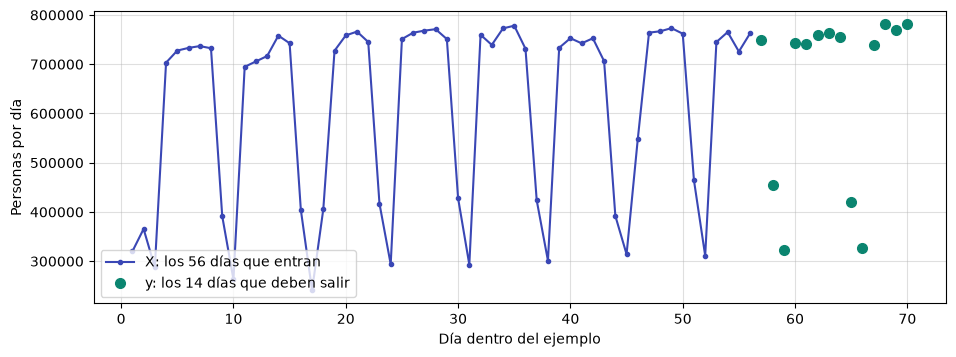

Forma de X: (56, 1)  Forma de y: (14,)


In [7]:
train_set = WindowDataset(rail_train)
valid_set = WindowDataset(rail_valid)
test_set = WindowDataset(rail_test)
windows_table(train_set)

X, y = train_set[0]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.arange(1, 57), X[:, 0] * scale, "o-", color=INDIGO, ms=3, label="X: los 56 días que entran")
ax.plot(np.arange(57, 71), y * scale, "o", color=TEAL, ms=7, label="y: los 14 días que deben salir")
ax.set_xlabel("Día dentro del ejemplo"); ax.set_ylabel("Personas por día"); ax.grid(alpha=0.4); ax.legend(loc="lower left")
plt.show()
print("Forma de X:", tuple(X.shape), " Forma de y:", tuple(y.shape))

### La red

`nn.GRU` entrega `outputs` (el estado de cada paso); nos quedamos solo con el último, `outputs[:, -1]`, y la capa densa lo convierte en 14 números. El argumento `target` no se usa: está para que las cuatro redes se llamen igual desde `Forecaster`.

In [8]:
class SeqToVector(nn.Module):
    def __init__(self, hidden_size=32, horizon=14):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, horizon)

    def forward(self, X, target=None):
        outputs, h_n = self.gru(X)          # outputs: (batch, 56, hidden_size)
        return self.head(outputs[:, -1])    # solo el último paso → (batch, 14)


torch.manual_seed(42)
seq_to_vector = Forecaster(SeqToVector())
seq_to_vector.fit(train_set, valid_set, epochs=100)

Entrenamiento: 100%|██████████| 100/100 [00:03<00:00, 27.21época/s, mae=46,994, mejor_val_mae=47,125, val_mae=51,579]

Mejor MAE de validación: 47,125 personas


El pronóstico de un ejemplo de test: la red lee las 8 semanas en índigo y entrega los 14 días en rojo. En verde, lo que de verdad pasó.

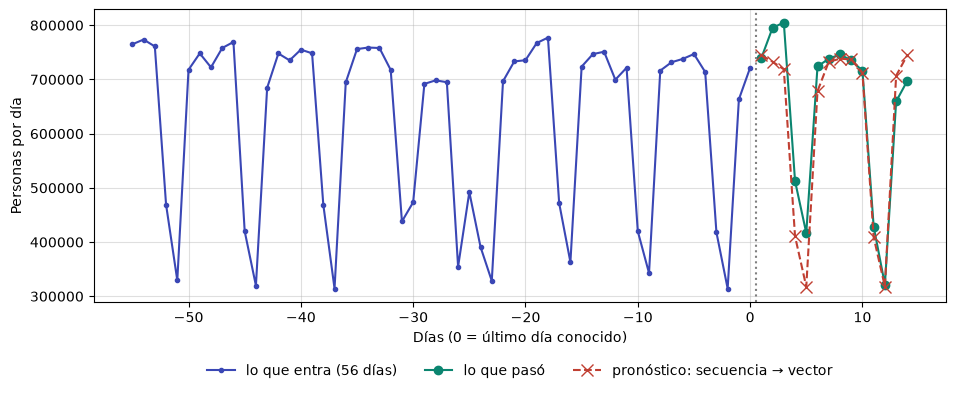

In [9]:
X_test, Y_test = stack(test_set)
example = 60   # un ejemplo cualquiera de test (prueben con otros)

def plot_forecast(Y_pred, label, i=example):
    past, future = np.arange(-window_length + 1, 1), np.arange(1, horizon + 1)
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(past, X_test[i, :, 0] * scale, ".-", color=INDIGO, label="lo que entra (56 días)")
    ax.plot(future, Y_test[i] * scale, "o-", color=TEAL, label="lo que pasó")
    ax.plot(future, Y_pred[i] * scale, "x--", color=CORAL, ms=8, label=label)
    ax.axvline(0.5, color="gray", ls=":")
    ax.set_xlabel("Días (0 = último día conocido)"); ax.set_ylabel("Personas por día")
    ax.grid(alpha=0.4); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
    plt.show()

Y_seq_to_vector = seq_to_vector.predict(X_test)
plot_forecast(Y_seq_to_vector, "pronóstico: secuencia → vector")

## Etapa 4: Arquitectura 2, secuencia → secuencia

**Qué entra:** la misma serie, $X = (x_1, \dots, x_{56})$. **Qué sale:** una predicción en **cada paso**, $\hat y_1, \dots, \hat y_{56}$, donde $\hat y_t$ es el pronóstico del día siguiente con lo leído hasta el paso $t$.

Por eso la etiqueta es la misma ventana **corrida un día**: si entran $x_1, \dots, x_{56}$, las respuestas correctas son $x_2, \dots, x_{57}$. La pérdida suma los errores de los 56 pasos, no solo del último: la red tiene más de qué aprender en cada ejemplo.

**La idea en nuestro problema.** Ahora pensemos en quien opera el metro **día a día**: cada noche, cuando ya conoce cuánta gente viajó hoy, quiere saber cuánta viajará **mañana** (por ejemplo, para reforzar una línea). Esta arquitectura hace justo eso: cada vez que llega un dato nuevo, entrega el pronóstico del día siguiente. Aquí **no** se pronostican varios días a la vez: cada salida es un solo día, el siguiente.

¿Y las dos semanas que necesita la CTA? Al final de la sección usamos esta misma red **paso a paso**: pronosticamos mañana, lo agregamos a la serie como si fuera un dato real y volvemos a pronosticar, 14 veces.

<img src="https://omarcastano.github.io/deeplearning-javeriana-site/modulo_2/unidad_2/3_experiencia/nueva/imagenes/arq2_secuencia_secuencia.png" alt="Secuencia → secuencia" width="620">

*Esquema de la presentación "Arquitecturas y práctica". Índigo: lo que entra. Verde: lo que sale.*

### Los ejemplos

Lo único que cambia es la etiqueta. En la tabla, $y_t = x_{t+1}$: la columna `y_1` es igual a `x_2`, `y_2` a `x_3`, y así. En la gráfica (solo los primeros días, para que se vea), cada círculo verde $y_t$ cae sobre el punto índigo del día siguiente, $x_{t+1}$.

,x_1,x_2,x_3,x_4,x_5,x_6,...,y_51,y_52,y_53,y_54,y_55,y_56
ejemplo 1,319835,365509,287661,703185,727716,733167,...,311190,745072,765309,725712,762858,749991
ejemplo 2,365509,287661,703185,727716,733167,736809,...,745072,765309,725712,762858,749991,455421
ejemplo 3,287661,703185,727716,733167,736809,732495,...,765309,725712,762858,749991,455421,323758
ejemplo 4,703185,727716,733167,736809,732495,391597,...,725712,762858,749991,455421,323758,742972
ejemplo 5,727716,733167,736809,732495,391597,263073,...,762858,749991,455421,323758,742972,741922


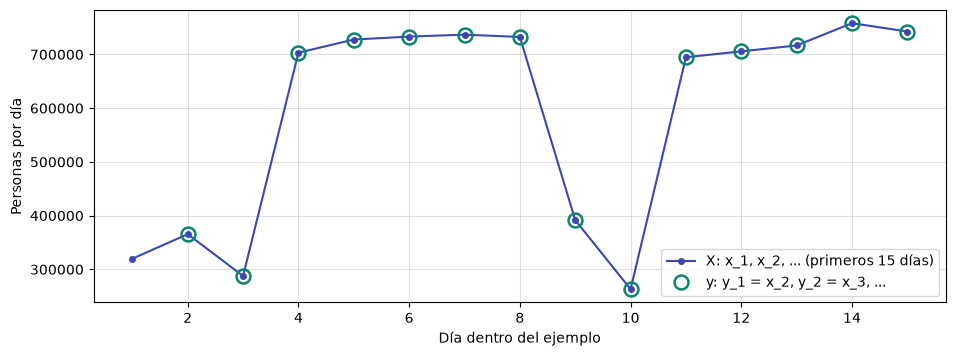

Forma de X: (56, 1)  Forma de y: (56,)


In [10]:
class SeqToSeqDataset(WindowDataset):
    # Etiqueta = la ventana corrida un día: y_t = x_(t+1)
    def __len__(self):
        return len(self.values) - self.window_length

    def __getitem__(self, idx):
        end = idx + self.window_length
        return self.values[idx:end].unsqueeze(-1), self.values[idx + 1:end + 1]   # (56, 1) y (56,)


train_set_2 = SeqToSeqDataset(rail_train)
valid_set_2 = SeqToSeqDataset(rail_valid)
windows_table(train_set_2)

X, y = train_set_2[0]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.arange(1, 16), X[:15, 0] * scale, "o-", color=INDIGO, ms=4, label="X: x_1, x_2, ... (primeros 15 días)")
ax.plot(np.arange(2, 16), y[:14] * scale, "o", color=TEAL, ms=10, mfc="none", mew=1.8, label="y: y_1 = x_2, y_2 = x_3, ...")
ax.set_xlabel("Día dentro del ejemplo"); ax.set_ylabel("Personas por día"); ax.grid(alpha=0.4); ax.legend(loc="lower right")
plt.show()
print("Forma de X:", tuple(X.shape), " Forma de y:", tuple(y.shape))

### La red

La diferencia con la arquitectura 1 está en una línea: la capa densa se aplica a `outputs` completo (los 56 estados), no solo al último. `nn.Linear` trabaja sobre la última dimensión, así que convierte cada estado $h_t$ en su $\hat y_t$ con los mismos pesos.

In [11]:
class SeqToSeq(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, X, target=None):
        outputs, h_n = self.gru(X)              # (batch, 56, hidden_size)
        return self.head(outputs).squeeze(-1)   # todos los pasos → (batch, 56)


torch.manual_seed(42)
seq_to_seq = Forecaster(SeqToSeq())
seq_to_seq.fit(train_set_2, valid_set_2, epochs=100)

Entrenamiento: 100%|██████████| 100/100 [00:03<00:00, 28.32época/s, mae=37,104, mejor_val_mae=57,332, val_mae=66,670]

Mejor MAE de validación: 57,332 personas


En un ejemplo de test, las predicciones de los 56 pasos (rojo) frente a lo que pasó al día siguiente (verde). Al principio la red ha leído pocos días y se equivoca más; a medida que lee la ventana, sus predicciones se acercan.

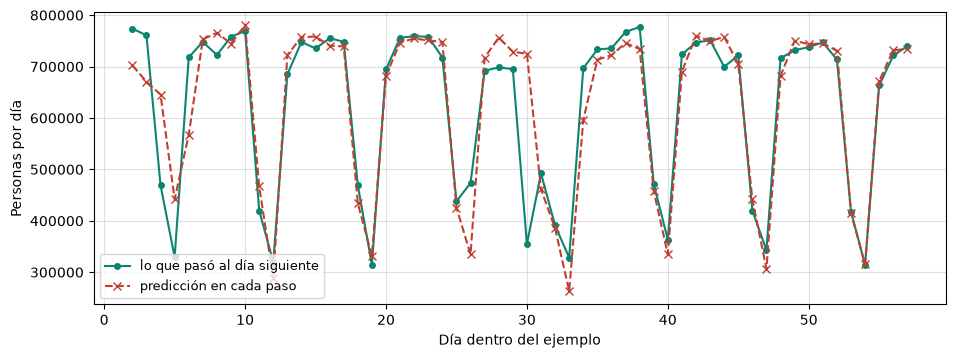

In [12]:
X, y = SeqToSeqDataset(rail_test)[example]
y_pred = seq_to_seq.predict(X.unsqueeze(0))[0]
t = np.arange(2, window_length + 2)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(t, y * scale, "o-", color=TEAL, ms=4, label="lo que pasó al día siguiente")
ax.plot(t, y_pred * scale, "x--", color=CORAL, label="predicción en cada paso")
ax.set_xlabel("Día dentro del ejemplo"); ax.set_ylabel("Personas por día"); ax.grid(alpha=0.4); ax.legend(loc="lower left", fontsize=9)
plt.show()

### Pronosticar 14 días paso a paso (autorregresivo)

Esta red solo pronostica **el día siguiente**. Para obtener 14 días usamos la **forma paso a paso** de la presentación, 14 veces seguidas:

1. Predice el día siguiente con la ventana actual (la última salida, $\hat y_{56}$).
2. Corre la ventana un día: quita el día más viejo y agrega **el pronóstico** al final, como si fuera un dato real.

<img src="https://omarcastano.github.io/deeplearning-javeriana-site/modulo_2/unidad_2/3_experiencia/nueva/imagenes/paso_a_paso.png" alt="Pronóstico paso a paso" width="620">

*Esquema de la presentación: en cada paso, el pronóstico (verde) entra a la ventana como si fuera un dato.*

A partir del segundo día la red lee sus propios pronósticos: si se equivoca un poco el día 1, ese error entra a la ventana y puede **acumularse**.

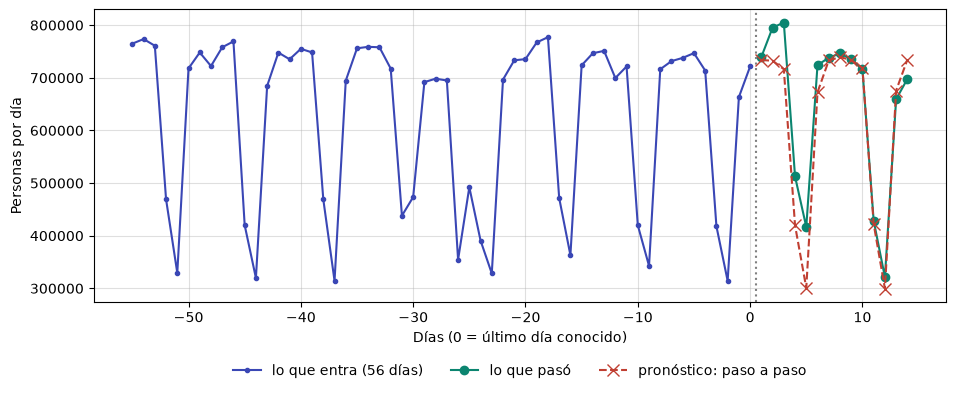

In [13]:
def forecast_step_by_step(forecaster, X, horizon=14):
    # X: (batch, 56, 1). Devuelve (batch, horizon)
    predictions = []
    for _ in range(horizon):
        y_next = forecaster.predict(X)[:, -1:]                   # la predicción del último paso: (batch, 1)
        predictions.append(y_next)
        X = torch.cat([X[:, 1:], y_next.unsqueeze(-1)], dim=1)  # corre la ventana un día
    return torch.cat(predictions, dim=1)


Y_step_by_step = forecast_step_by_step(seq_to_seq, X_test)
plot_forecast(Y_step_by_step, "pronóstico: paso a paso")

## Etapa 5: Arquitectura 3, vector → secuencia

**Qué entra:** un solo vector, con unos pocos números que describen la situación; no hay historia que leer. **Qué sale:** una serie de 14 días, que la red genera un valor por paso.

**La idea en nuestro problema.** Las dos arquitecturas anteriores necesitan los 56 días de historia. Pero muchas veces no se tiene la historia completa, o no hace falta: para planear basta con **describir la situación** con unos pocos números. Por ejemplo: "las dos semanas empiezan un lunes, estamos en marzo y la semana pasada viajaron en promedio 650 000 personas por día". Con esa descripción, una persona con experiencia ya podría dibujar más o menos las dos semanas: cinco días altos, un sábado más bajo, un domingo aún más bajo, y otra vez.

Eso es lo que aprende esta red: a partir del vector, **genera** la serie de 14 días. La genera **un día a la vez** y no los 14 juntos porque cada día depende del anterior: después de un viernes alto viene un sábado bajo. Por eso cada pronóstico entra como dato al paso siguiente.

¿Qué números describen las próximas dos semanas del metro? Usamos nueve:

- **Día de la semana** en que empieza el pronóstico, con 7 números (`lun` a `dom`): un 1 en el día que corresponde y 0 en los demás.
- **Mes**, dividido entre 12 (enero = 0.08, diciembre = 1).
- **Promedio de la última semana**: cuánta gente viajó en promedio en los 7 días anteriores (dividido entre un millón).

<img src="https://omarcastano.github.io/deeplearning-javeriana-site/modulo_2/unidad_2/3_experiencia/nueva/imagenes/arq3_vector_secuencia.png" alt="Vector → secuencia" width="620">

*Esquema de la presentación "Arquitecturas y práctica". Índigo: lo que entra. Verde: lo que sale.*

In [14]:
class VectorDataset(WindowDataset):
    # Los mismos ejemplos de WindowDataset, pero X es un vector de 9 números en vez de 56 días
    def __getitem__(self, idx):
        end = idx + self.window_length
        first_day = self.dates[end]                             # primer día que se pronostica
        weekday = torch.zeros(7)
        weekday[first_day.day_of_week] = 1.0                      # lun = 0, ..., dom = 6
        month = torch.tensor([first_day.month / 12])
        last_week = self.values[end - 7:end].mean().reshape(1)
        v = torch.cat([weekday, month, last_week])              # (9,)
        y = self.values[end:end + self.horizon]                 # (14,), igual que en WindowDataset
        return v, y


train_set_3 = VectorDataset(rail_train)
valid_set_3 = VectorDataset(rail_valid)
test_set_3 = VectorDataset(rail_test)

columns = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom", "mes", "promedio_semana"]
rows = [torch.cat(train_set_3[i]).numpy() for i in range(5)]
table = pd.DataFrame(rows, columns=columns + [f"y_{h + 1}" for h in range(horizon)],
                     index=[f"ejemplo {i + 1}" for i in range(5)])
table[columns[:7]] = table[columns[:7]].astype(int)
table[[f"y_{h + 1}" for h in range(horizon)]] = (table[[f"y_{h + 1}" for h in range(horizon)]] * scale).round().astype(int)
with pd.option_context("display.max_columns", 16):
    display(table.round(2))

,lun,mar,mié,jue,vie,sáb,dom,mes,...,y_7,y_8,y_9,y_10,y_11,y_12,y_13,y_14
ejemplo 1,0,0,0,0,1,0,0,0.17,...,764033,754750,421193,327173,739174,781301,768961,780687
ejemplo 2,0,0,0,0,0,1,0,0.17,...,754750,421193,327173,739174,781301,768961,780687,797977
ejemplo 3,0,0,0,0,0,0,1,0.17,...,421193,327173,739174,781301,768961,780687,797977,605182
ejemplo 4,1,0,0,0,0,0,0,0.17,...,327173,739174,781301,768961,780687,797977,605182,303129
ejemplo 5,0,1,0,0,0,0,0,0.25,...,739174,781301,768961,780687,797977,605182,303129,766595


En la tabla, cada fila es un ejemplo: las nueve primeras columnas forman el vector X y las columnas `y_1` a `y_14` forman y. En la gráfica, el vector del primer ejemplo (izquierda) y los 14 días que la red debe generar a partir de él (derecha).

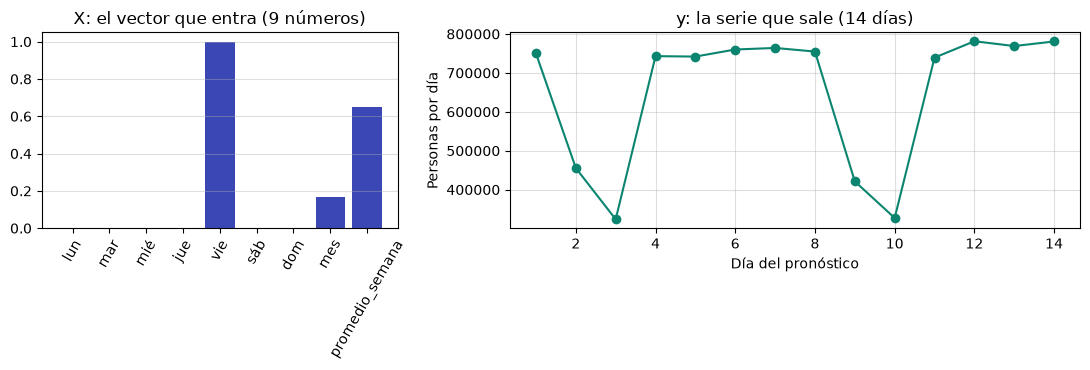

Forma de X: (9,)  Forma de y: (14,)


In [15]:
v, y = train_set_3[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax1.bar(columns, v, color=INDIGO)
ax1.set_title("X: el vector que entra (9 números)"); ax1.tick_params(axis="x", rotation=60); ax1.grid(alpha=0.4, axis="y")
ax2.plot(np.arange(1, horizon + 1), y * scale, "o-", color=TEAL)
ax2.set_title("y: la serie que sale (14 días)"); ax2.set_xlabel("Día del pronóstico"); ax2.set_ylabel("Personas por día")
ax2.grid(alpha=0.4)
plt.tight_layout(); plt.show()
print("Forma de X:", tuple(v.shape), " Forma de y:", tuple(y.shape))

### La red: un decodificador

Esta red tiene dos partes nuevas:

1. **El vector entra al primer paso:** una capa densa lo convierte en el estado inicial de la memoria, $h_0$.
2. **Un decodificador** genera los 14 días uno por uno con `nn.GRUCell`, que es **un solo paso** de una GRU: recibe un valor y el estado anterior y devuelve el estado nuevo. Lo llamamos 14 veces dentro de un `for`. En cada paso, una capa densa convierte el estado en $\hat y_t$, y ese $\hat y_t$ es la entrada del paso siguiente (**autorregresivo**). En el primer paso no hay valor anterior, así que entra un 0.

**Al entrenar** se usa *teacher forcing*, como vimos en la presentación: en cada paso el decodificador recibe el **valor real** del día anterior (`target`), no su predicción. Así aprende más rápido, porque un error al principio no daña los pasos siguientes. Al pronosticar de verdad no conoce los valores reales y usa sus propias predicciones.

Escribimos el decodificador como una clase aparte porque la arquitectura 4 lo vuelve a usar.

In [16]:
class Decoder(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.cell = nn.GRUCell(input_size=1, hidden_size=hidden_size)   # un paso de una GRU
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, h, first_input, horizon=14, target=None):
        # h: estado inicial (batch, hidden_size); first_input: entrada del primer paso (batch, 1)
        y_prev, predictions = first_input, []
        for t in range(horizon):
            h = self.cell(y_prev, h)            # un paso: nuevo estado
            y_t = self.head(h)                  # predicción del paso t: (batch, 1)
            predictions.append(y_t)
            if target is not None:              # al entrenar: el valor real (teacher forcing)
                y_prev = target[:, t:t + 1]
            else:                               # al pronosticar: su propia predicción
                y_prev = y_t
        return torch.cat(predictions, dim=1)    # (batch, 14)


class VectorToSeq(nn.Module):
    def __init__(self, n_features=9, hidden_size=32, horizon=14):
        super().__init__()
        self.to_state = nn.Linear(n_features, hidden_size)   # vector → estado inicial h_0
        self.decoder = Decoder(hidden_size)
        self.horizon = horizon

    def forward(self, v, target=None):
        h0 = torch.tanh(self.to_state(v))                    # (batch, hidden_size)
        first_input = torch.zeros(len(v), 1, device=v.device)
        return self.decoder(h0, first_input, self.horizon, target)


torch.manual_seed(42)
vector_to_seq = Forecaster(VectorToSeq())
vector_to_seq.fit(train_set_3, valid_set_3, epochs=100)

Entrenamiento: 100%|██████████| 100/100 [00:11<00:00,  8.94época/s, mae=36,980, mejor_val_mae=40,883, val_mae=59,212]

Mejor MAE de validación: 40,883 personas


El pronóstico del mismo ejemplo de test. Ojo: esta red no vio los 56 días en índigo (se dibujan solo como referencia); solo recibió los nueve números del vector.

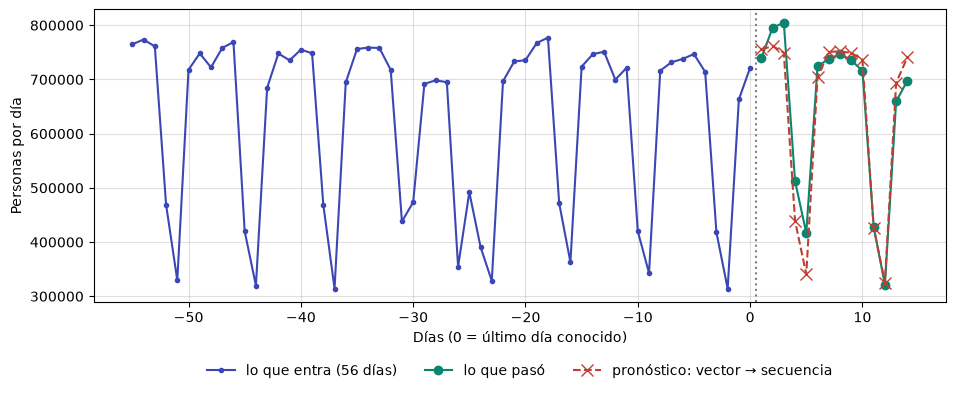

In [17]:
V_test, Y_test_3 = stack(test_set_3)
assert torch.equal(Y_test_3, Y_test)   # los mismos 14 días que en las otras arquitecturas
Y_vector_to_seq = vector_to_seq.predict(V_test)
plot_forecast(Y_vector_to_seq, "pronóstico: vector → secuencia")

## Etapa 6: Arquitectura 4, codificador–decodificador

**Qué entra:** la serie de los últimos 56 días. **Qué sale:** otra serie, de 14 días: otro largo.

**La idea en nuestro problema.** Es otra vez la pregunta de la CTA (los próximos 14 días a partir de los últimos 56), pero ahora juntando lo mejor de las dos arquitecturas anteriores: como en la arquitectura 1, la red **lee toda la historia**; como en la arquitectura 3, **genera los 14 días uno por uno**, cada uno a partir del anterior. Lo que entra (56 días) y lo que sale (14 días) tienen distinto largo, y eso no es problema: una parte de la red se encarga de leer y otra de escribir.

Junta las dos anteriores:

- **Codificador** (como la arquitectura 1): una GRU lee los 56 días. Su último estado es el **contexto**, un vector que resume la ventana.
- **Decodificador** (como la arquitectura 3, la misma clase `Decoder`): parte del contexto y genera los 14 días uno por uno. Su primera entrada es el último día conocido, $x_{56}$; después, cada predicción entra al paso siguiente. Al entrenar usa *teacher forcing*.

La diferencia con la arquitectura 3 es de dónde sale el estado inicial: allá de nueve números escogidos a mano; aquí, de lo que la red aprendió a resumir leyendo los 56 días.

<img src="https://omarcastano.github.io/deeplearning-javeriana-site/modulo_2/unidad_2/3_experiencia/nueva/imagenes/arq4_codificador_decodificador.png" alt="Codificador–decodificador" width="620">

*Esquema de la presentación "Arquitecturas y práctica". Índigo: lo que entra. Verde: lo que sale.*

Los ejemplos son los mismos de la arquitectura 1 (`WindowDataset`): X son los 56 días de historia, $X = (x_1, \dots, x_{56})$, e y los 14 días siguientes, $y = (y_1, \dots, y_{14})$. La tabla y la gráfica de la etapa 3 sirven igual aquí. Solo cambia la red.

Entrenamiento: 100%|██████████| 100/100 [00:10<00:00,  9.24época/s, mae=37,442, mejor_val_mae=46,675, val_mae=50,156]


Mejor MAE de validación: 46,675 personas


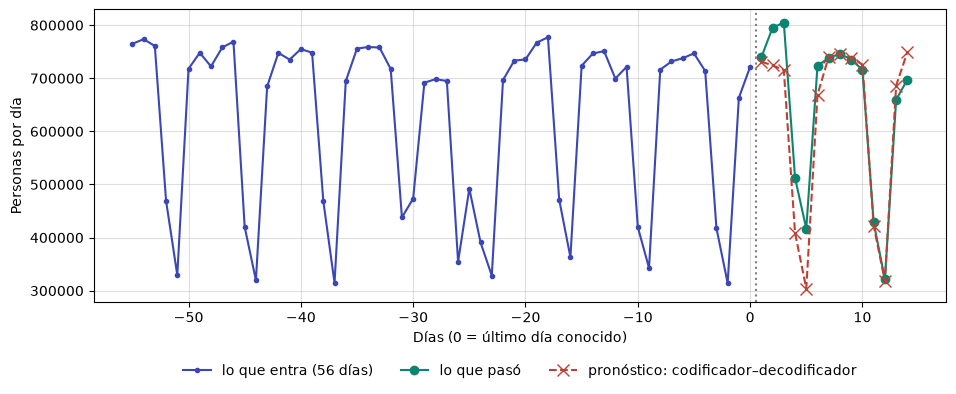

In [18]:
class EncoderDecoder(nn.Module):
    def __init__(self, hidden_size=32, horizon=14):
        super().__init__()
        self.encoder = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.decoder = Decoder(hidden_size)
        self.horizon = horizon

    def forward(self, X, target=None):
        outputs, h_n = self.encoder(X)     # h_n: (1, batch, hidden_size), el último estado
        context = h_n[0]                   # el contexto: (batch, hidden_size)
        last_value = X[:, -1]              # x_56, primera entrada del decodificador: (batch, 1)
        return self.decoder(context, last_value, self.horizon, target)


torch.manual_seed(42)
encoder_decoder = Forecaster(EncoderDecoder())
encoder_decoder.fit(train_set, valid_set, epochs=100)

Y_encoder_decoder = encoder_decoder.predict(X_test)
plot_forecast(Y_encoder_decoder, "pronóstico: codificador–decodificador")

## Etapa 7: ¿Cuál se equivoca menos?

Comparamos en test los cuatro pronósticos de 14 días y, como referencia, el pronóstico ingenuo: cada día futuro es igual al mismo día de la semana anterior que está dentro de la ventana. Medimos el MAE **por separado para cada día del horizonte**: el error de pronosticar mañana, el de pasado mañana, …, el de dentro de 14 días.

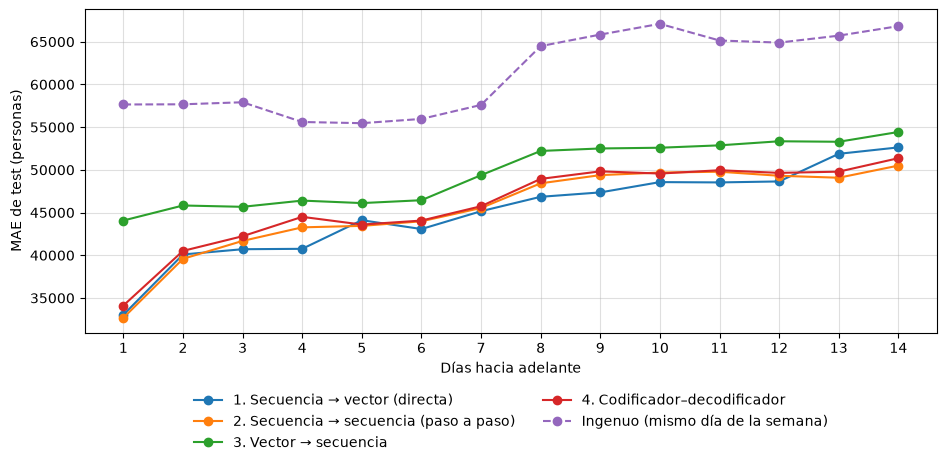

,MAE promedio de test (personas)
1. Secuencia → vector (directa),45097
2. Secuencia → secuencia (paso a paso),45451
3. Vector → secuencia,49653
4. Codificador–decodificador,45988
Ingenuo (mismo día de la semana),61276


In [19]:
# Ingenuo: el día h se pronostica con el mismo día de la semana dentro de la última semana de la ventana
Y_naive = torch.stack([X_test[:, -7 + (h % 7), 0] for h in range(horizon)], dim=1)

forecasts = {
    "1. Secuencia → vector (directa)": Y_seq_to_vector,
    "2. Secuencia → secuencia (paso a paso)": Y_step_by_step,
    "3. Vector → secuencia": Y_vector_to_seq,
    "4. Codificador–decodificador": Y_encoder_decoder,
    "Ingenuo (mismo día de la semana)": Y_naive,
}
days = np.arange(1, horizon + 1)
fig, ax = plt.subplots(figsize=(11, 4.2))
summary = {}
for name, Y_pred in forecasts.items():
    errors = ((Y_pred - Y_test).abs().mean(dim=0) * scale).numpy()
    summary[name] = errors.mean()
    ax.plot(days, errors, marker="o", ls="--" if name.startswith("Ingenuo") else "-", label=name)
ax.set_xlabel("Días hacia adelante"); ax.set_ylabel("MAE de test (personas)")
ax.set_xticks(days); ax.grid(alpha=0.4)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.show()

pd.Series(summary, name="MAE promedio de test (personas)").round().astype(int).to_frame()

Para leer la gráfica y la tabla (los números cambian un poco en cada ejecución):

- **Las cuatro arquitecturas le ganan al pronóstico ingenuo** en todos los días del horizonte.
- **El error crece a medida que miramos más lejos:** pronosticar mañana es más fácil que pronosticar dentro de dos semanas.
- **Las tres que leen la serie** (1, 2 y 4) quedan muy parecidas. En esta serie, cuyo patrón semanal es muy regular, el error de la forma paso a paso casi no se acumula. En series más irregulares la diferencia suele ser mayor, y por eso conviene probar varias.
- **Vector → secuencia queda un poco peor,** sobre todo en los primeros días: solo conoce el día de la semana, el mes y el promedio de la última semana, no lo que pasó ayer. Aun así le gana al ingenuo. Es la arquitectura para cuando no hay historia que leer, como el producto nuevo o el día de mañana descrito por unos pocos números de la presentación.

Con esto tenemos las cuatro arquitecturas programadas con las mismas piezas: una GRU que lee (codificador), una capa densa al final de la lectura o en cada paso, y un decodificador que genera un valor por paso.